# 12. 최종 일기 감정 분석 시스템 성능 평가

**작성자: 김민서**

이 노트북은 `11_diary_system_user.ipynb`의 **분석 로직을 수정하지 않고**,  
내장된 30개 데모 일기의 **목표 대표 감정과 실제 예측 대표 감정**을 비교하는 평가용 노트북입니다.

## 평가 항목
1. 30개 일기별 목표 감정 vs 예측 감정
2. 전체 대표 감정 정확도
3. 감정별 정확도
4. 목표 감정과 예측 감정의 혼동 행렬(Confusion Matrix)
5. 자주 발생한 오분류 유형
6. 틀린 일기 목록

> 이 평가 결과는 현재 최종 시스템의 성능과 한계를 확인하기 위한 것이며,  
> 평가 결과에 따라 11의 분석 로직을 다시 수정하는 것을 목적으로 하지 않습니다.


In [1]:
# 1. 평가 데이터 준비
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.utils.capture import capture_output

cwd = Path.cwd()
notebooks_dir = cwd if cwd.name == "notebooks" else cwd / "notebooks"
project_root = notebooks_dir.parent
output_dir = project_root / "outputs"
data_dir = project_root / "data"

notebook_11 = notebooks_dir / "11_diary_system_user.ipynb"

target_path = data_dir / "sample_diary_11_demo_targets_v2.csv"
prediction_path = output_dir / "diary_daily_11_demo_2026_09.csv"

if not notebook_11.exists():
    raise FileNotFoundError(
        f"11번 최종 노트북을 찾을 수 없습니다:\n{notebook_11}"
    )

def evaluation_files_ready():
    """기존 11 실행 결과가 평가에 사용 가능한지 확인한다."""
    if not target_path.exists() or not prediction_path.exists():
        return False

    try:
        target = pd.read_csv(target_path, encoding="utf-8-sig")
        pred = pd.read_csv(prediction_path, encoding="utf-8-sig")

        required_target = {"date", "text", "target_emotion", "sentence_count"}
        required_pred = {"date", "main_emotion", "top_emotions"}

        if not required_target <= set(target.columns):
            return False
        if not required_pred <= set(pred.columns):
            return False

        if len(target) != 30 or len(pred) != 30:
            return False

        if set(target["date"].astype(str)) != set(pred["date"].astype(str)):
            return False

        return True

    except Exception:
        return False


if evaluation_files_ready():
    print("11에서 생성된 데모 분석 결과를 불러옵니다.")
else:
    print("평가용 결과가 없어 11의 분석 초기화를 한 번 실행합니다.")

    notebook_data = json.loads(
        notebook_11.read_text(encoding="utf-8")
    )

    if len(notebook_data.get("cells", [])) < 2:
        raise RuntimeError("11번 노트북의 구조를 확인할 수 없습니다.")

    startup_source = "".join(
        notebook_data["cells"][1].get("source", [])
    )

    # 버튼 UI는 실행하지 않고, 모델/데모 분석 초기화 셀만 실행한다.
    with capture_output():
        exec(
            compile(
                startup_source,
                "11_diary_system_user.ipynb:startup",
                "exec"
            ),
            globals()
        )

    if not evaluation_files_ready():
        raise RuntimeError(
            "11 초기화 후에도 30개 데모 평가 파일을 생성하지 못했습니다."
        )

targets = pd.read_csv(target_path, encoding="utf-8-sig")
predictions = pd.read_csv(prediction_path, encoding="utf-8-sig")

print("목표 데이터:", len(targets), "개")
print("예측 데이터:", len(predictions), "개")


11에서 생성된 데모 분석 결과를 불러옵니다.
목표 데이터: 30 개
예측 데이터: 30 개


In [2]:
from matplotlib import font_manager

for font_name in [
    "Malgun Gothic",
    "AppleGothic",
    "NanumGothic",
    "Noto Sans CJK KR"
]:
    if any(
        font_name == item.name
        for item in font_manager.fontManager.ttflist
    ):
        plt.rcParams["font.family"] = font_name
        break

plt.rcParams["axes.unicode_minus"] = False

In [3]:
# 2. 30개 데모 일기 목표 감정 vs 예측 감정 비교

target_table = targets[
    ["date", "target_emotion", "sentence_count", "text"]
].copy()

prediction_columns = [
    "date",
    "main_emotion",
    "top_emotions",
]

# 있는 경우 발표/분석에 유용한 추가 열도 함께 사용
for column in [
    "positive_score",
    "negative_score",
    "neutral_score",
    "representative_score",
    "runner_up_emotion",
    "representative_gap",
    "dominance_level",
]:
    if column in predictions.columns:
        prediction_columns.append(column)

prediction_table = predictions[prediction_columns].copy()

target_table["date"] = target_table["date"].astype(str)
prediction_table["date"] = prediction_table["date"].astype(str)

evaluation = target_table.merge(
    prediction_table,
    on="date",
    how="inner",
    validate="one_to_one"
)

evaluation["정답"] = (
    evaluation["target_emotion"] == evaluation["main_emotion"]
)

evaluation["정답 여부"] = np.where(
    evaluation["정답"],
    "O",
    "X"
)

evaluation = evaluation.rename(columns={
    "date": "날짜",
    "target_emotion": "목표 감정",
    "main_emotion": "예측 감정",
    "sentence_count": "문장 수",
    "text": "일기",
    "top_emotions": "세부 감정 Top5",
    "positive_score": "긍정 점수",
    "negative_score": "부정 점수",
    "neutral_score": "중립 점수",
    "representative_score": "대표 감정 점수",
    "runner_up_emotion": "2순위 감정",
    "representative_gap": "대표 감정 격차",
    "dominance_level": "우세도",
})

if len(evaluation) != 30:
    raise RuntimeError(
        f"평가 데이터가 30개가 아닙니다: {len(evaluation)}개"
    )

summary_columns = [
    "날짜", "목표 감정", "예측 감정",
    "정답 여부", "문장 수", "세부 감정 Top5"
]

display(evaluation[summary_columns])

print(
    f"\n평가 대상: {len(evaluation)}개 "
    f"(정답 {evaluation['정답'].sum()} / "
    f"오답 {(~evaluation['정답']).sum()})"
)


,날짜,목표 감정,예측 감정,정답 여부,문장 수,세부 감정 Top5
0,2026-09-01,분노,슬픔,X,5,"안타까움/실망, 힘듦/지침, 당황/난처, 짜증, 불평/불만"
1,2026-09-02,기대,기대,O,2,"기대감, 신기함/관심, 환영/호의, 안심/신뢰, 감동/감탄"
2,2026-09-03,슬픔,슬픔,O,4,"슬픔, 힘듦/지침, 불쌍함/연민, 불안/걱정, 깨달음"
3,2026-09-04,피로,피로,O,4,"힘듦/지침, 절망, 지긋지긋, 슬픔, 서러움"
4,2026-09-05,중립,행복,X,4,"편안/쾌적, 힘듦/지침, 행복, 기쁨, 뿌듯함"
5,2026-09-06,분노,분노,O,3,"짜증, 불안/걱정, 불평/불만, 당황/난처, 화남/분노"
6,2026-09-07,중립,행복,X,4,"편안/쾌적, 뿌듯함, 힘듦/지침, 행복, 안심/신뢰"
7,2026-09-08,분노,분노,O,3,"짜증, 불평/불만, 지긋지긋, 당황/난처, 힘듦/지침"
8,2026-09-09,기대,기대,O,5,"기대감, 힘듦/지침, 환영/호의, 신기함/관심, 아껴주는"
9,2026-09-10,불안,불안,O,4,"불안/걱정, 힘듦/지침, 안타까움/실망, 불쌍함/연민, 슬픔"



평가 대상: 30개 (정답 24 / 오답 6)


In [4]:
# 3. 전체 정확도

correct_count = int(evaluation["정답"].sum())
total_count = len(evaluation)
overall_accuracy = correct_count / total_count

print("=" * 50)
print("전체 대표 감정 정확도")
print("=" * 50)
print(f"정답: {correct_count} / {total_count}")
print(f"정확도: {overall_accuracy:.1%}")


전체 대표 감정 정확도
정답: 24 / 30
정확도: 80.0%


In [5]:
# 4. 감정별 정확도

EMOTION_ORDER = [
    "행복", "기대", "슬픔", "분노", "불안", "피로", "중립"
]

emotion_accuracy = (
    evaluation
    .groupby("목표 감정", observed=False)["정답"]
    .agg(["sum", "count", "mean"])
    .rename(columns={
        "sum": "정답 수",
        "count": "전체 수",
        "mean": "정확도"
    })
)

emotion_accuracy = emotion_accuracy.reindex(EMOTION_ORDER)
emotion_accuracy["오답 수"] = (
    emotion_accuracy["전체 수"] - emotion_accuracy["정답 수"]
)
emotion_accuracy["정확도(%)"] = (
    emotion_accuracy["정확도"] * 100
).round(1)

emotion_accuracy = emotion_accuracy[
    ["전체 수", "정답 수", "오답 수", "정확도(%)"]
]

display(emotion_accuracy)


,전체 수,정답 수,오답 수,정확도(%)
목표 감정,,,,
행복,5,5,0,100.0
기대,5,4,1,80.0
슬픔,4,4,0,100.0
분노,4,3,1,75.0
불안,4,4,0,100.0
피로,4,4,0,100.0
중립,4,0,4,0.0


예측 감정,행복,기대,슬픔,분노,불안,피로,중립
목표 감정,,,,,,,
행복,5,0,0,0,0,0,0
기대,1,4,0,0,0,0,0
슬픔,0,0,4,0,0,0,0
분노,0,0,1,3,0,0,0
불안,0,0,0,0,4,0,0
피로,0,0,0,0,0,4,0
중립,4,0,0,0,0,0,0


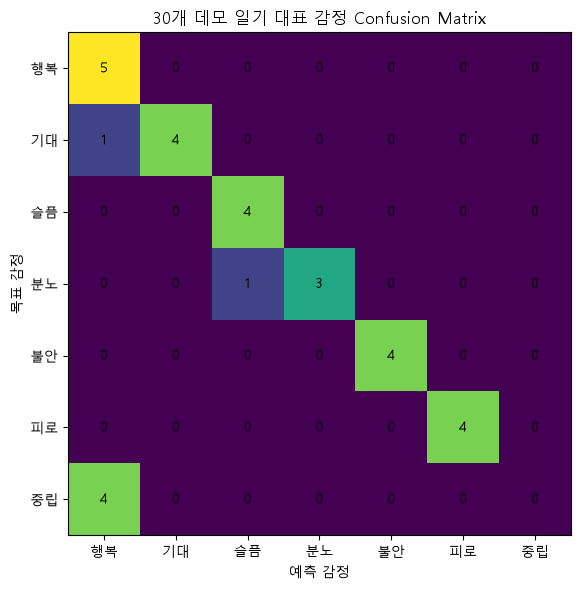


[오분류 유형]


,목표 감정,예측 감정,횟수
0,중립,행복,4
1,분노,슬픔,1
2,기대,행복,1


In [6]:
# 5. Confusion Matrix + 주요 오분류 유형

confusion = pd.crosstab(
    evaluation["목표 감정"],
    evaluation["예측 감정"],
    rownames=["목표 감정"],
    colnames=["예측 감정"],
    dropna=False
).reindex(
    index=EMOTION_ORDER,
    columns=EMOTION_ORDER,
    fill_value=0
)

display(confusion)

# 혼동 행렬 시각화
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(confusion.to_numpy())

ax.set_xticks(range(len(EMOTION_ORDER)))
ax.set_xticklabels(EMOTION_ORDER)
ax.set_yticks(range(len(EMOTION_ORDER)))
ax.set_yticklabels(EMOTION_ORDER)

ax.set_xlabel("예측 감정")
ax.set_ylabel("목표 감정")
ax.set_title("30개 데모 일기 대표 감정 Confusion Matrix")

for i in range(len(EMOTION_ORDER)):
    for j in range(len(EMOTION_ORDER)):
        ax.text(
            j,
            i,
            int(confusion.iloc[i, j]),
            ha="center",
            va="center"
        )

fig.tight_layout()
plt.show()
plt.close(fig)

# 어떤 감정을 무엇으로 가장 많이 잘못 예측했는지
wrong_only = evaluation.loc[
    ~evaluation["정답"],
    ["목표 감정", "예측 감정"]
]

if wrong_only.empty:
    print("오분류가 없습니다.")
else:
    confusion_pairs = (
        wrong_only
        .value_counts()
        .rename("횟수")
        .reset_index()
    )

    print("\n[오분류 유형]")
    display(confusion_pairs)


In [7]:
# 6. 틀린 일기 목록

wrong_cases = (
    evaluation.loc[
        ~evaluation["정답"]
    ]
    .copy()
    .reset_index(drop=True)
)

if wrong_cases.empty:
    print("30개 일기를 모두 정확하게 분류했습니다.")
else:
    wrong_display_columns = [
        "날짜",
        "목표 감정",
        "예측 감정",
        "세부 감정 Top5",
        "일기",
    ]

    # 존재하는 분석 열은 추가로 표시
    for column in [
        "긍정 점수",
        "부정 점수",
        "중립 점수",
        "2순위 감정",
        "대표 감정 격차",
        "우세도",
    ]:
        if column in wrong_cases.columns:
            wrong_display_columns.append(column)

    print(f"오답 수: {len(wrong_cases)}개")
    display(wrong_cases[wrong_display_columns])


오답 수: 6개


,날짜,목표 감정,예측 감정,세부 감정 Top5,일기,긍정 점수,부정 점수,중립 점수,2순위 감정,대표 감정 격차,우세도
0,2026-09-01,분노,슬픔,"안타까움/실망, 힘듦/지침, 당황/난처, 짜증, 불평/불만",조별 과제를 하는데 한 팀원이 맡은 일을 거의 준비하지 않았다. 결국 다른 사람들이...,0.238,0.772,0.294,분노,0.049,낮음
1,2026-09-05,중립,행복,"편안/쾌적, 힘듦/지침, 행복, 기쁨, 뿌듯함",오늘은 정해진 시간에 수업에 참석했다. 수업이 끝난 뒤 집으로 와서 간단히 저녁을 ...,0.792,0.706,0.658,피로,0.086,보통
2,2026-09-07,중립,행복,"편안/쾌적, 뿌듯함, 힘듦/지침, 행복, 안심/신뢰",오늘 아침에 학교에 가서 오전 수업을 들었다. 점심을 먹은 뒤 도서관에서 필요한 자...,0.809,0.674,0.718,피로,0.135,보통
3,2026-09-12,중립,행복,"편안/쾌적, 힘듦/지침, 뿌듯함, 행복, 기쁨",오늘은 평소와 비슷한 시간에 일어나 준비한 뒤 학교에 가서 수업을 들었다. 수업이 ...,0.845,0.774,0.672,피로,0.071,낮음
4,2026-09-19,중립,행복,"편안/쾌적, 뿌듯함, 기쁨, 행복, 안심/신뢰",오전에는 온라인 강의를 듣고 내용을 노트에 정리했다. 오후에는 빨래를 하고 책상 위...,0.879,0.669,0.795,피로,0.210,높음
5,2026-09-21,기대,행복,"기대감, 편안/쾌적, 행복, 즐거움/신남, 기쁨",이번 주말에는 가족들과 오랜만에 외식을 하기로 했고 평소 가 보고 싶었던 식당에 갈...,0.847,0.256,0.266,기대,0.129,보통


In [8]:
# 7. 평가 결과 저장
# 발표 자료나 보고서에서 바로 사용할 수 있도록 CSV로 저장한다.

evaluation_output = output_dir / "evaluation_12_results.csv"
emotion_output = output_dir / "evaluation_12_emotion_accuracy.csv"
confusion_output = output_dir / "evaluation_12_confusion_matrix.csv"
wrong_output = output_dir / "evaluation_12_wrong_cases.csv"

evaluation.to_csv(
    evaluation_output,
    index=False,
    encoding="utf-8-sig"
)

emotion_accuracy.to_csv(
    emotion_output,
    encoding="utf-8-sig"
)

confusion.to_csv(
    confusion_output,
    encoding="utf-8-sig"
)

wrong_cases.to_csv(
    wrong_output,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료")
print("-", evaluation_output.name)
print("-", emotion_output.name)
print("-", confusion_output.name)
print("-", wrong_output.name)


저장 완료
- evaluation_12_results.csv
- evaluation_12_emotion_accuracy.csv
- evaluation_12_confusion_matrix.csv
- evaluation_12_wrong_cases.csv


## 평가 결과 해석 방법

이 평가의 목적은 **현재 최종 시스템의 대표 감정 판정 성능과 한계를 확인하는 것**입니다.

발표에서는 다음처럼 정리하면 됩니다.

- 전체 30개 일기 중 대표 감정을 몇 개 정확히 맞혔는지 제시
- 행복·기대·슬픔·분노·불안·피로·중립별 정확도 비교
- 오답이 발생한 경우 어떤 대표 감정끼리 혼동했는지 확인
- 대표 감정이 틀렸더라도 `세부 감정 Top5`에 목표 감정과 관련된 감정이 포함됐는지도 함께 관찰
- 오분류 사례는 향후 개선 방향으로 제시

**중요:** 이 노트북은 평가용이며 `11_diary_system_user.ipynb`의 분석 로직을 변경하지 않습니다.
